# Corner Cases and Edge Cases

**Module 02 · Failures and Robustness** · Notebook 2 of 4

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/02_Failures_and_Robustness/02_corner_cases.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Beginner | [01 · Incident case studies](01_incident_case_studies.ipynb); [01 · SAE levels and ODD](../01_Perception/01_sae_levels_and_odd.ipynb) | ISO 21448:2022, ISO 34502:2022, ISO 34503:2023 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook, you will be able to:

1. Distinguish edge cases from corner cases, and the test-engineering from the perception (ML) usage of "corner case"
2. Explain the long-tail problem and why rare scenarios matter for validation effort
3. Identify and organise corner cases using corner-case levels and the ISO 34502 disturbance categories
4. Quantify combinatorial explosion and reduce it with pairwise (combinatorial) testing
5. Separate in-ODD corner cases from ODD-exit conditions and prioritise testing consistently
6. Relate corner cases to ISO 21448 triggering conditions and functional insufficiencies

## Setup and imports

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from IPython.display import display

OKABE = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
rng = np.random.default_rng(42)

print(f"NumPy {np.__version__} | pandas {pd.__version__}")

NumPy 2.5.4 | pandas 3.1.0


---

## Definitions: edge cases vs corner cases

### Edge cases

**Definition (test engineering):** a scenario in which **one parameter** is at the **boundary of the Operational Design Domain (ODD)**, all others nominal.

**Characteristics:**
- One parameter at its limit; well-defined, predictable locations in parameter space
- Can be tested systematically (boundary-value analysis)

**Examples** (for an ODD that allows them):
- Maximum permitted speed (e.g. 60 km/h)
- Minimum visibility (e.g. 50 m in fog)
- Maximum rain intensity (e.g. 50 mm/h)
- Steepest permitted grade (e.g. 15%)

### Corner cases

**Definition (test engineering):** a scenario in which **several parameters are simultaneously** at or near their limits — the "corners" of the parameter space.

**Characteristics:**
- Combinations of parameters; rare in the real world
- Exponentially many possibilities (combinatorial explosion)
- Easily overlooked in testing

**Examples:**
- Maximum speed + heavy rain + sharp curve + pedestrian crossing
- Low sun glare + wet road + cyclist + construction zone

> **Note — two usages exist.**
> (1) **Test engineering** (this notebook's main thread): combinations of parameter extremes.
> (2) **Perception / machine learning:** a *corner case* is a **rare or novel situation that challenges the model**, organised in levels — *pixel*, *domain*, *object*, *scene* and *scenario* level (Breitenstein et al., 2020; Heidecker et al., 2021). A single unusual object (an inflatable costume) can be a corner case in the second sense without any parameter being at an ODD limit.
> **ISO 21448 itself does not use the term "corner case"**; it speaks of **triggering conditions** that activate **functional insufficiencies** (see the last section).

### Visual comparison

Illustrative ODD limits: speed 0-60 km/h, rain 0-50 mm/h (chosen for teaching).


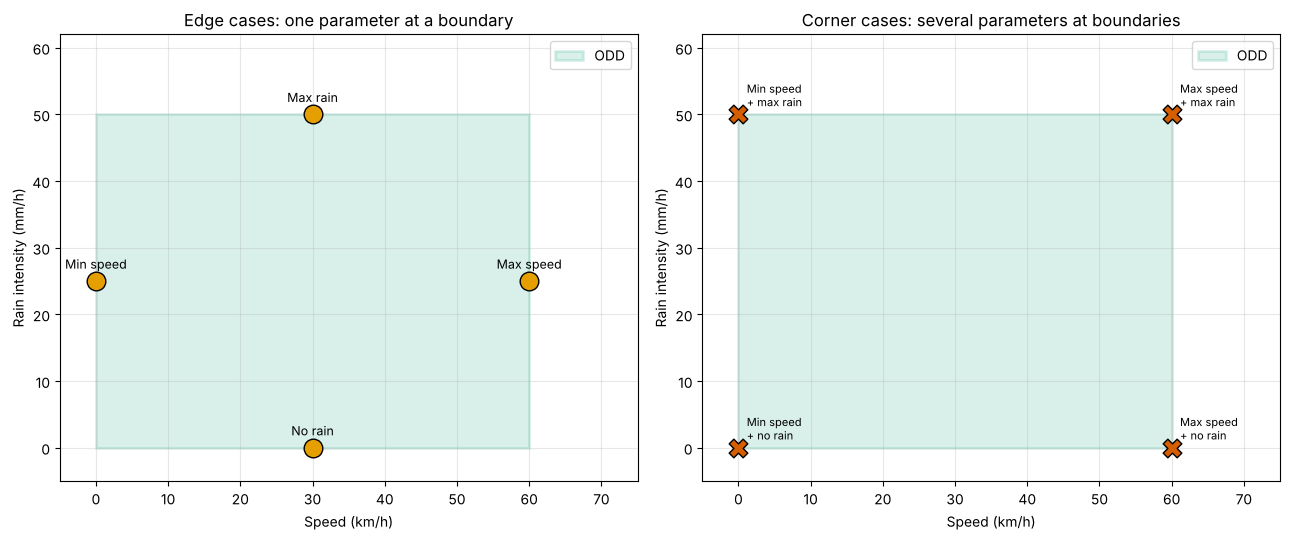

--- Text summary ---
  Edge cases  : 4 points, one parameter at its limit each
  Corner cases: 4 points = 2^2 corners of a 2-parameter ODD; with k parameters there are 2^k corners


In [2]:
print("Illustrative ODD limits: speed 0-60 km/h, rain 0-50 mm/h (chosen for teaching).")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, title in zip(axes, ['Edge cases: one parameter at a boundary', 'Corner cases: several parameters at boundaries']):
    ax.add_patch(Rectangle((0, 0), 60, 50, facecolor=OKABE[2], alpha=0.15, edgecolor=OKABE[2], lw=2, label='ODD'))
    ax.set_xlabel('Speed (km/h)')
    ax.set_ylabel('Rain intensity (mm/h)')
    ax.set_xlim(-5, 75)
    ax.set_ylim(-5, 62)
    ax.set_title(title)

edge_cases = [(60, 25, 'Max speed'), (30, 50, 'Max rain'), (0, 25, 'Min speed'), (30, 0, 'No rain')]
for x, y, label in edge_cases:
    axes[0].scatter(x, y, s=180, color=OKABE[0], edgecolors='k', zorder=5)
    axes[0].annotate(label, (x, y), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9)
corner_cases_2d = [(60, 50, 'Max speed\n+ max rain'), (60, 0, 'Max speed\n+ no rain'),
                   (0, 50, 'Min speed\n+ max rain'), (0, 0, 'Min speed\n+ no rain')]
for x, y, label in corner_cases_2d:
    axes[1].scatter(x, y, s=180, marker='X', color=OKABE[5], edgecolors='k', zorder=5)
    axes[1].annotate(label, (x, y), xytext=(6, 6), textcoords='offset points', fontsize=8)
for ax in axes:
    ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

print("--- Text summary ---")
print(f"  Edge cases  : {len(edge_cases)} points, one parameter at its limit each")
print(f"  Corner cases: {len(corner_cases_2d)} points = 2^2 corners of a 2-parameter ODD; "
      "with k parameters there are 2^k corners")

---

## The long tail in automated driving

Most driving exposure consists of a few common situations; a very large number of situation types each occur rarely. A frequently used **teaching assumption** is a Pareto-like split ("80% of miles are routine, a small share of exposure produces most safety-critical events").

> **Illustrative assumption:** the Pareto split is a heuristic, **not an empirical AV statistic**.

A well-founded quantitative argument comes from **Kalra & Paddock (2016)**: demonstrating, with 95% confidence and no failures, that an automated fleet's fatality rate is below the 2013 US human-driver rate of **1.09 fatalities per 100 million miles** requires about **275 million failure-free miles**. The calculation is a simple Poisson (zero-failure) bound — computed below. Rare events dominate the *validation effort*, which is why the long tail matters.

**Head (common):** clear weather, daytime, standard vehicles, good roads
**Tail (rare but potentially critical):** unusual weather (sandstorm, ice storm), rare objects (escaped livestock, furniture on the road), infrastructure anomalies (missing signs, temporary layouts), compound situations

**Challenge for ML:** models trained mostly on the head generalise worse to the tail.

In [3]:
# Zero-failure demonstration: P(0 failures in n miles) = exp(-rate * n) <= 1 - confidence
rate_human = 1.09e-8          # fatalities per mile (2013 US, as used by Kalra & Paddock 2016)
confidence = 0.95
n_miles = -np.log(1 - confidence) / rate_human
print(f"Failure-free miles needed: {n_miles / 1e6:,.0f} million "
      f"(to show rate < {rate_human * 1e8:.2f} per 100 M miles with {confidence:.0%} confidence)")
print("The same calculation is available as avsafety.validation.miles_to_demonstrate (see repo avsafety/); "
      "treated in depth in Module 06, statistical safety validation.")

Failure-free miles needed: 275 million (to show rate < 1.09 per 100 M miles with 95% confidence)
The same calculation is available as avsafety.validation.miles_to_demonstrate (see repo avsafety/); treated in depth in Module 06, statistical safety validation.


> Illustrative data: values below are synthetic, chosen for teaching; they are not measurements.


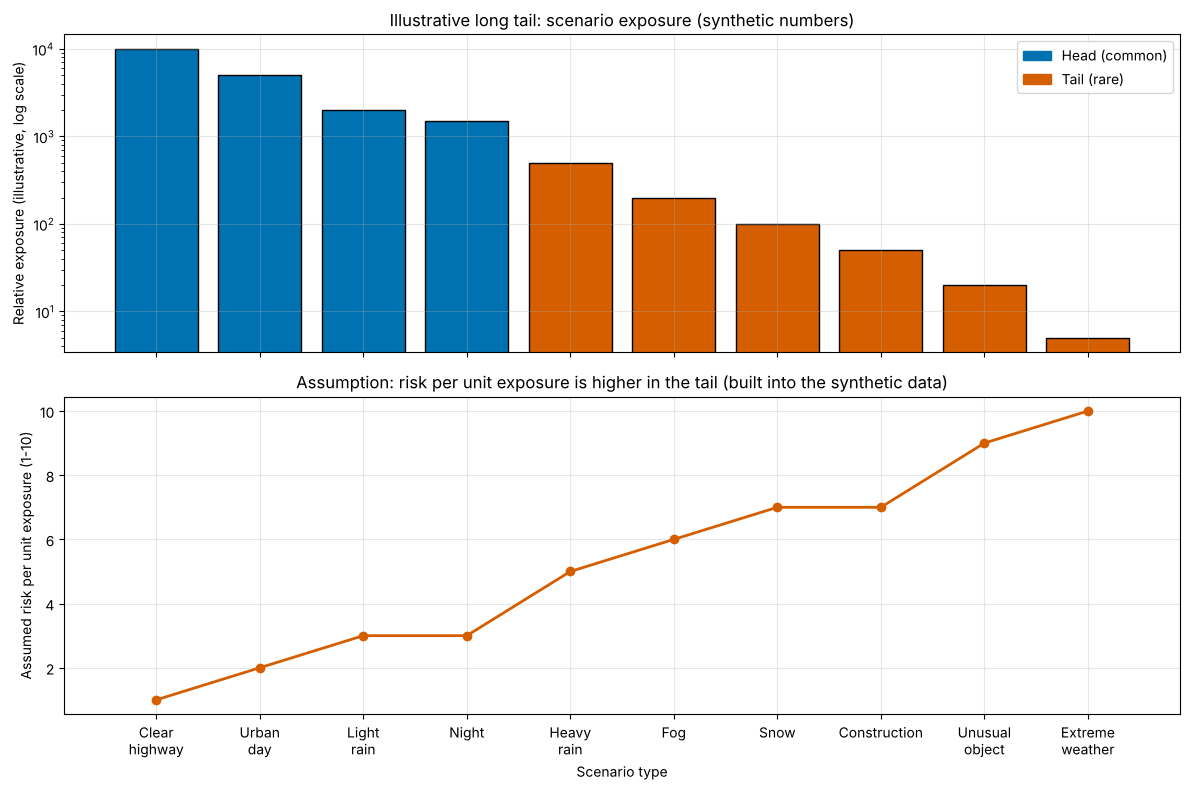

--- Derived from the illustrative numbers ---
  Tail share of exposure            : 4.5%
  Tail share of exposure-weighted risk: 14.0%
  Interpretation: with these assumptions the tail is a small share of exposure but a larger share
  of risk; whether that holds for a real system must be shown with field and test data.


In [4]:
print("> Illustrative data: values below are synthetic, chosen for teaching; they are not measurements.")
scenarios = ['Clear\nhighway', 'Urban\nday', 'Light\nrain', 'Night', 'Heavy\nrain',
             'Fog', 'Snow', 'Construction', 'Unusual\nobject', 'Extreme\nweather']
exposure = np.array([10000, 5000, 2000, 1500, 500, 200, 100, 50, 20, 5], dtype=float)  # relative exposure
risk_per_exposure = np.array([1, 2, 3, 3, 5, 6, 7, 7, 9, 10], dtype=float)           # assumed, relative
is_tail = np.arange(len(scenarios)) >= 4

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.bar(range(len(scenarios)), exposure, color=np.where(is_tail, OKABE[5], OKABE[4]), edgecolor='k')
ax1.set_yscale('log')
ax1.set_ylabel('Relative exposure (illustrative, log scale)')
ax1.set_title('Illustrative long tail: scenario exposure (synthetic numbers)')
ax1.legend(handles=[Rectangle((0, 0), 1, 1, color=OKABE[4], label='Head (common)'),
                    Rectangle((0, 0), 1, 1, color=OKABE[5], label='Tail (rare)')])
ax2.plot(range(len(scenarios)), risk_per_exposure, marker='o', color=OKABE[5], lw=2)
ax2.set_ylabel('Assumed risk per unit exposure (1-10)')
ax2.set_xlabel('Scenario type')
ax2.set_title('Assumption: risk per unit exposure is higher in the tail (built into the synthetic data)')
ax2.set_xticks(range(len(scenarios)))
ax2.set_xticklabels(scenarios)
plt.tight_layout()
plt.show()

contribution = exposure * risk_per_exposure
print("--- Derived from the illustrative numbers ---")
print(f"  Tail share of exposure            : {exposure[is_tail].sum() / exposure.sum():.1%}")
print(f"  Tail share of exposure-weighted risk: {contribution[is_tail].sum() / contribution.sum():.1%}")
print("  Interpretation: with these assumptions the tail is a small share of exposure but a larger share")
print("  of risk; whether that holds for a real system must be shown with field and test data.")

---

## Organising corner cases

### Categories used in this notebook

**1. Environmental:** sandstorm; black ice; flooding over lane markings; low sun causing camera saturation
**2. Infrastructure:** missing or faded markings; contradictory signs; construction zones with temporary signals; potholes
**3. Traffic participants:** escaped animals; oversized loads; emergency vehicles; pedestrians in unexpected places
**4. Sensor-related:** contaminated sensors; reflections (wet roads, glass façades); mutual LiDAR interference
**5. Compound:** night + rain + construction + pedestrian; fog + narrow road + oncoming truck + cyclist

### Two systematic views

- **Corner-case levels** (Breitenstein et al., 2020): *pixel* (e.g. glare, dead pixels), *domain* (e.g. a new country or weather), *object* (unknown object type), *scene* (known objects in an unusual constellation) and *scenario* (an unusual sequence over time).
- **ISO 34502:2022** (scenario-based safety evaluation framework for ADS) derives critical scenarios from three groups of disturbances: **perception-related**, **traffic-related** and **vehicle-motion-related**.

In [5]:
print("> Illustrative data: frequency, risk and test status are assumptions for a fictional system.")
corner_cases = pd.DataFrame([
    # category, scenario, frequency, risk, tested, corner-case level, ISO 34502 disturbance
    ('Environmental', 'Sandstorm', 'Very rare', 'Critical', 'No', 'domain', 'perception'),
    ('Environmental', 'Black ice', 'Rare', 'Critical', 'Partial', 'domain', 'vehicle motion'),
    ('Environmental', 'Flooding', 'Rare', 'High', 'Partial', 'domain', 'perception / vehicle motion'),
    ('Environmental', 'Low sun glare', 'Common', 'High', 'Yes', 'pixel', 'perception'),
    ('Infrastructure', 'Missing lane markings', 'Common', 'High', 'Yes', 'scene', 'perception'),
    ('Infrastructure', 'Contradictory signs', 'Rare', 'High', 'No', 'scene', 'perception'),
    ('Infrastructure', 'Construction zone', 'Common', 'High', 'Yes', 'scene', 'traffic'),
    ('Infrastructure', 'Large potholes', 'Common', 'Medium', 'Yes', 'object', 'vehicle motion'),
    ('Traffic', 'Escaped animals', 'Very rare', 'Critical', 'No', 'object', 'traffic'),
    ('Traffic', 'Oversized load', 'Rare', 'High', 'Partial', 'object', 'traffic'),
    ('Traffic', 'Emergency vehicle', 'Rare', 'High', 'Yes', 'scenario', 'traffic'),
    ('Traffic', 'Mid-block crossing at night', 'Rare', 'Critical', 'Partial', 'scenario', 'traffic / perception'),
    ('Sensor', 'Contaminated camera', 'Common', 'Medium', 'Yes', 'pixel', 'perception'),
    ('Sensor', 'LiDAR mutual interference', 'Rare', 'Medium', 'Partial', 'pixel', 'perception'),
    ('Sensor', 'Wet-road reflections', 'Common', 'Medium', 'Yes', 'pixel', 'perception'),
    ('Compound', 'Night + rain + construction', 'Rare', 'Critical', 'No', 'scenario', 'perception / traffic'),
    ('Compound', 'Fog + narrow road + truck', 'Rare', 'Critical', 'No', 'scenario', 'perception / traffic'),
    ('Compound', 'Snow + GNSS outage + unclear lanes', 'Very rare', 'Critical', 'No', 'scenario', 'perception / vehicle motion'),
], columns=['Category', 'Scenario', 'Frequency', 'Risk', 'Tested', 'Corner_case_level', 'ISO34502_disturbance'])
display(corner_cases)

not_tested = corner_cases[corner_cases['Tested'] == 'No']
critical_not_tested = not_tested[not_tested['Risk'] == 'Critical']
print("--- Testing gaps (derived) ---")
print(f"  Total scenarios            : {len(corner_cases)}")
print(f"  Not fully tested           : {int((corner_cases['Tested'] != 'Yes').sum())}")
print(f"  Critical and not tested    : {len(critical_not_tested)} -> {list(critical_not_tested['Scenario'])}")
print("  Corner-case levels         : " + ", ".join(f"{k}: {v}" for k, v in corner_cases['Corner_case_level'].value_counts().items()))

> Illustrative data: frequency, risk and test status are assumptions for a fictional system.


,Category,Scenario,Frequency,Risk,Tested,Corner_case_level,ISO34502_disturbance
0,Environmental,Sandstorm,Very rare,Critical,No,domain,perception
1,Environmental,Black ice,Rare,Critical,Partial,domain,vehicle motion
2,Environmental,Flooding,Rare,High,Partial,domain,perception / vehicle motion
3,Environmental,Low sun glare,Common,High,Yes,pixel,perception
4,Infrastructure,Missing lane markings,Common,High,Yes,scene,perception
5,Infrastructure,Contradictory signs,Rare,High,No,scene,perception
6,Infrastructure,Construction zone,Common,High,Yes,scene,traffic
7,Infrastructure,Large potholes,Common,Medium,Yes,object,vehicle motion
8,Traffic,Escaped animals,Very rare,Critical,No,object,traffic
9,Traffic,Oversized load,Rare,High,Partial,object,traffic


--- Testing gaps (derived) ---
  Total scenarios            : 18
  Not fully tested           : 11
  Critical and not tested    : 5 -> ['Sandstorm', 'Escaped animals', 'Night + rain + construction', 'Fog + narrow road + truck', 'Snow + GNSS outage + unclear lanes']
  Corner-case levels         : scenario: 5, pixel: 4, domain: 3, scene: 3, object: 3


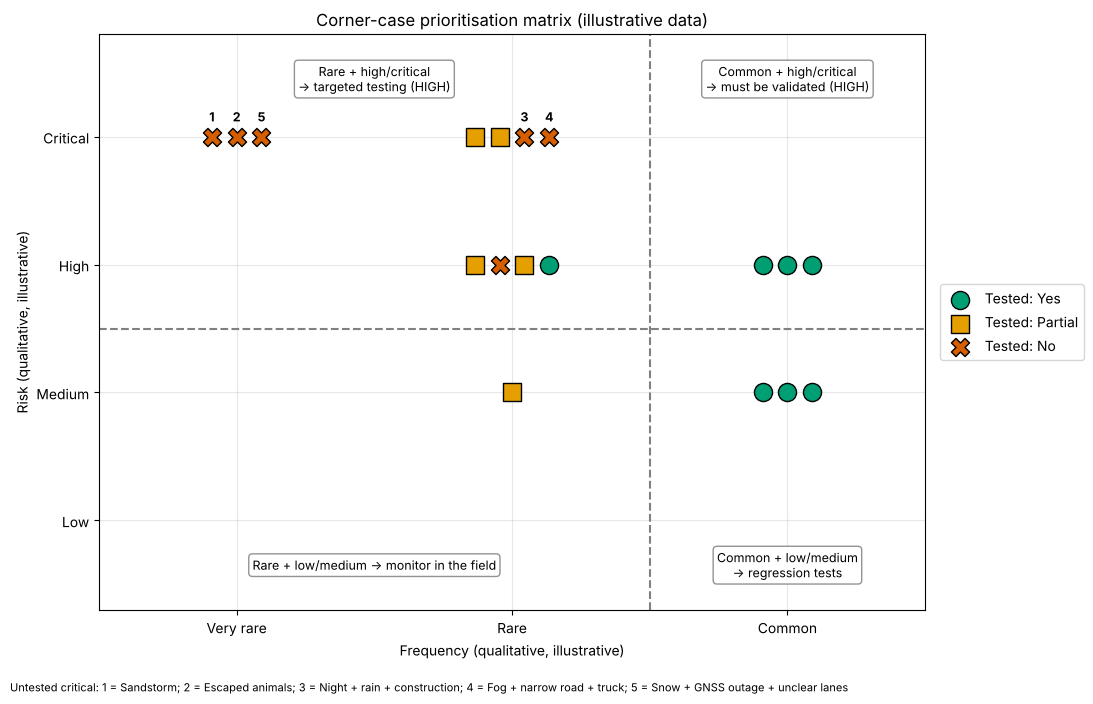

--- Prioritisation (derived) ---
  Rare + high/critical   : 11 scenarios, 10 not fully tested
  Common + high/critical : 3 scenarios, 0 not fully tested
  Untested critical scenarios: Sandstorm, Escaped animals, Night + rain + construction, Fog + narrow road + truck, Snow + GNSS outage + unclear lanes


In [6]:
risk_map = {'Low': 1, 'Medium': 2, 'High': 3, 'Critical': 4}
freq_map = {'Very rare': 1, 'Rare': 2, 'Common': 3}
corner_cases['Risk_Score'] = corner_cases['Risk'].map(risk_map)
corner_cases['Freq_Score'] = corner_cases['Frequency'].map(freq_map)
critical_not_tested = corner_cases[(corner_cases['Tested'] == 'No') & (corner_cases['Risk'] == 'Critical')]

# small deterministic offsets so that points in the same cell do not hide each other
offs = corner_cases.groupby(['Freq_Score', 'Risk_Score']).cumcount()
n_in_cell = corner_cases.groupby(['Freq_Score', 'Risk_Score'])['Scenario'].transform('count')
dx = (offs - (n_in_cell - 1) / 2) * 0.09

style = {'Yes': (OKABE[2], 'o'), 'Partial': (OKABE[0], 's'), 'No': (OKABE[5], 'X')}
fig, ax = plt.subplots(figsize=(11, 7))
for status, (col, mk) in style.items():
    m = corner_cases['Tested'] == status
    ax.scatter(corner_cases.loc[m, 'Freq_Score'] + dx[m], corner_cases.loc[m, 'Risk_Score'],
               s=170, color=col, marker=mk, edgecolors='k', label=f'Tested: {status}', zorder=3)

# Quadrants: rare (very rare + rare) vs common; low/medium vs high/critical
ax.axvline(2.5, color='grey', ls='--')
ax.axhline(2.5, color='grey', ls='--')
quad = [(1.5, 4.45, 'Rare + high/critical\n-> targeted testing (HIGH)'),
        (3.0, 4.45, 'Common + high/critical\n-> must be validated (HIGH)'),
        (1.5, 0.65, 'Rare + low/medium -> monitor in the field'),
        (3.0, 0.65, 'Common + low/medium\n-> regression tests')]
for x, y, t in quad:
    ax.text(x, y, t, ha='center', va='center', fontsize=9,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='grey'))
key = []
for k, (_, r) in enumerate(critical_not_tested.iterrows(), 1):
    i = r.name
    ax.annotate(str(k), (r['Freq_Score'] + dx[i], r['Risk_Score']), xytext=(0, 11),
                textcoords='offset points', ha='center', fontsize=9, fontweight='bold')
    key.append(f"{k} = {r['Scenario']}")
fig.text(0.01, 0.005, 'Untested critical: ' + '; '.join(key), fontsize=8)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(['Very rare', 'Rare', 'Common'])
ax.set_yticks([1, 2, 3, 4])
ax.set_yticklabels(['Low', 'Medium', 'High', 'Critical'])
ax.set_xlim(0.5, 3.5)
ax.set_ylim(0.3, 4.8)
ax.set_xlabel('Frequency (qualitative, illustrative)')
ax.set_ylabel('Risk (qualitative, illustrative)')
ax.set_title('Corner-case prioritisation matrix (illustrative data)')
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

hi = corner_cases[corner_cases['Risk_Score'] >= 3]
print("--- Prioritisation (derived) ---")
print(f"  Rare + high/critical   : {int((hi['Freq_Score'] <= 2).sum())} scenarios, "
      f"{int(((hi['Freq_Score'] <= 2) & (hi['Tested'] != 'Yes')).sum())} not fully tested")
print(f"  Common + high/critical : {int((hi['Freq_Score'] == 3).sum())} scenarios, "
      f"{int(((hi['Freq_Score'] == 3) & (hi['Tested'] != 'Yes')).sum())} not fully tested")
print("  Untested critical scenarios: " + ", ".join(critical_not_tested['Scenario']))

> **Two prioritisation logics — and why both are needed.** A *likelihood × severity* ranking (used for the campus shuttle below) favours **frequent** scenarios. For long-tail safety we additionally need **exposure-independent coverage of severe scenarios** (the "rare + high/critical" quadrant above). ISO 21448 handles this via **acceptance criteria and validation targets** (e.g. the residual risk of the intended functionality, or required driving distance), rather than through a single risk matrix.

---

## Combinatorial explosion

**Example:** an automated campus shuttle with 5 parameters, 3 values each:
- Weather: {Clear, Rain, Fog}
- Time: {Day, Dusk, Night}
- Traffic: {Light, Medium, Heavy}
- Road: {Dry, Wet, Icy}
- Obstacles: {None, Pedestrian, Construction}

**All combinations:** 3^5 = **243**. With 10 parameters: 3^10 = **59,049** — and real scenario spaces also contain continuous parameters (speeds, distances, timing).

Parameter space:
  Weather: 3 values - ['Clear', 'Rain', 'Fog']
  Time: 3 values - ['Day', 'Dusk', 'Night']
  Traffic: 3 values - ['Light', 'Medium', 'Heavy']
  Road: 3 values - ['Dry', 'Wet', 'Icy']
  Obstacles: 3 values - ['None', 'Pedestrian', 'Construction']

Total combinations: 243
First 5 combinations:
  1. Weather:Clear, Time:Day, Traffic:Light, Road:Dry, Obstacles:None
  2. Weather:Clear, Time:Day, Traffic:Light, Road:Dry, Obstacles:Pedestrian
  3. Weather:Clear, Time:Day, Traffic:Light, Road:Dry, Obstacles:Construction
  4. Weather:Clear, Time:Day, Traffic:Light, Road:Wet, Obstacles:None
  5. Weather:Clear, Time:Day, Traffic:Light, Road:Wet, Obstacles:Pedestrian


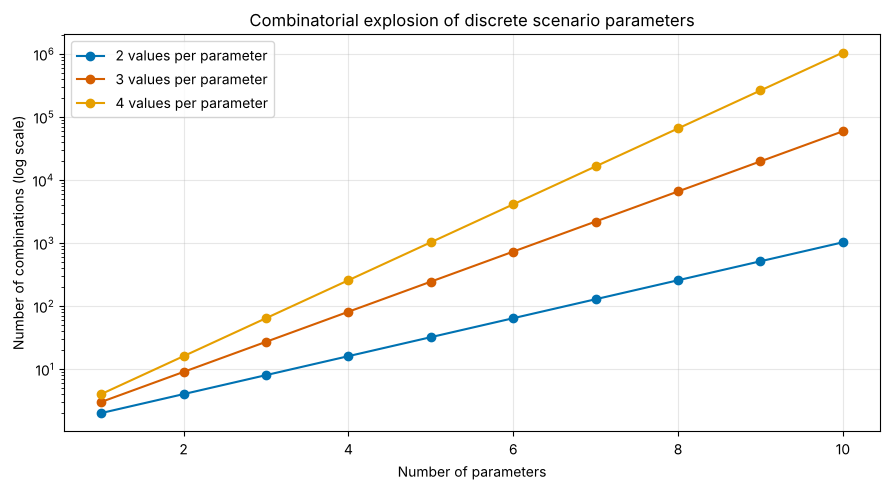

--- Text summary --- 3 values: 243 combinations for 5 parameters, 59,049 for 10 parameters.


In [7]:
parameters = {
    'Weather': ['Clear', 'Rain', 'Fog'],
    'Time': ['Day', 'Dusk', 'Night'],
    'Traffic': ['Light', 'Medium', 'Heavy'],
    'Road': ['Dry', 'Wet', 'Icy'],
    'Obstacles': ['None', 'Pedestrian', 'Construction'],
}
all_combinations = list(itertools.product(*parameters.values()))

print("Parameter space:")
for p, v in parameters.items():
    print(f"  {p}: {len(v)} values - {v}")
print(f"\nTotal combinations: {len(all_combinations)}")
print("First 5 combinations:")
for i, combo in enumerate(all_combinations[:5], 1):
    print(f"  {i}. " + ', '.join(f"{p}:{v}" for p, v in zip(parameters, combo)))

num_params = np.arange(1, 11)
fig, ax = plt.subplots(figsize=(9, 5))
for k, col in zip([2, 3, 4], [OKABE[4], OKABE[5], OKABE[0]]):
    ax.plot(num_params, k ** num_params.astype(float), marker='o', color=col, label=f'{k} values per parameter')
ax.set_yscale('log')
ax.set_xlabel('Number of parameters')
ax.set_ylabel('Number of combinations (log scale)')
ax.set_title('Combinatorial explosion of discrete scenario parameters')
ax.legend()
plt.tight_layout()
plt.show()
print(f"--- Text summary --- 3 values: {3**5} combinations for 5 parameters, {3**10:,} for 10 parameters.")

### Reducing the test set: pairwise (combinatorial) testing

Field studies in software engineering found that most failures are triggered by interactions of **one or two** parameters, and very few by more than six (Kuhn, Wallace & Gallo, 2004). A **pairwise covering array** contains every value pair of every two parameters at least once — far fewer tests than all combinations. Higher strengths (3-way, 4-way) are a systematic middle ground. Tools such as NIST ACTS generate such arrays; below is a simple greedy construction.

> Caveat: pairwise coverage says nothing about *continuous* parameters or rare interactions of three or more factors (exactly the "corner cases" above). It complements, but does not replace, risk-based and search-based testing.

In [8]:
names = list(parameters)

def pairs_of(test):
    return {((i, test[i]), (j, test[j])) for i, j in itertools.combinations(range(len(test)), 2)}

required = set()
for i, j in itertools.combinations(range(len(names)), 2):
    for a in parameters[names[i]]:
        for b in parameters[names[j]]:
            required.add(((i, a), (j, b)))

# Greedy: repeatedly pick the combination that covers the most still-uncovered pairs
uncovered, pairwise_tests = set(required), []
while uncovered:
    best = max(all_combinations, key=lambda t: len(pairs_of(t) & uncovered))
    pairwise_tests.append(best)
    uncovered -= pairs_of(best)

pairwise_df = pd.DataFrame(pairwise_tests, columns=names)
display(pairwise_df)
covered = set().union(*(pairs_of(t) for t in pairwise_tests))
print(f"Required value pairs : {len(required)}")
print(f"Pairwise test set    : {len(pairwise_tests)} tests cover {len(covered & required)}/{len(required)} pairs "
      f"({len(pairwise_tests) / len(all_combinations):.1%} of all {len(all_combinations)} combinations)")

,Weather,Time,Traffic,Road,Obstacles
0,Clear,Day,Light,Dry,None
1,Clear,Dusk,Medium,Wet,Pedestrian
2,Clear,Night,Heavy,Icy,Construction
3,Rain,Day,Light,Wet,Construction
4,Rain,Dusk,Medium,Icy,None
5,Rain,Night,Heavy,Dry,Pedestrian
6,Fog,Day,Light,Icy,Pedestrian
7,Fog,Dusk,Medium,Dry,Construction
8,Fog,Night,Heavy,Wet,None
9,Clear,Day,Medium,Dry,None


Required value pairs : 90
Pairwise test set    : 15 tests cover 90/90 pairs (6.2% of all 243 combinations)


---

## Simulation-based testing

**Why simulation:**
1. **Scalability:** many scenarios per day
2. **Safety:** no risk to people or property
3. **Reproducibility:** exact replay
4. **Coverage:** systematic exploration of parameter space
5. **Cost:** cheaper per scenario than road testing

**Limitations:**
1. **Sim-to-real gap:** models of physics, sensors and behaviour are approximations
2. **Sensor modelling:** rain, glare and material properties are hard to model faithfully
3. **Unknown hazardous scenarios:** simulation cannot *guarantee* their discovery, but **search-based, adversarial and importance-sampling methods** help find them (e.g. Feng et al., 2023)
4. **Validation:** simulation results themselves must be validated against real data

**Best practice — hybrid approach:** simulation for breadth, proving ground and public roads for validation, field data to update the scenario catalogue.

Below, scenarios are sampled from an assumed **operational distribution** (common conditions are frequent). We measure **parameter-combination coverage** — the share of the 243 discrete combinations seen at least once. This is not "scenario coverage" in the ISO 21448 sense, which also concerns continuous parameters and unknown scenarios.

> Illustrative data: the sampling probabilities are assumptions, not measured exposure.
Simulated scenarios          : 10,000
Distinct combinations covered: 213 / 243 (87.7%)
Combinations never sampled   : 30
Values over-represented among the never-sampled combinations:
  Weather  : Fog (14 of 30)
  Time     : Dusk (14 of 30)
  Traffic  : Heavy (13 of 30)
  Road     : Icy (25 of 30)
  Obstacles: Construction (22 of 30)


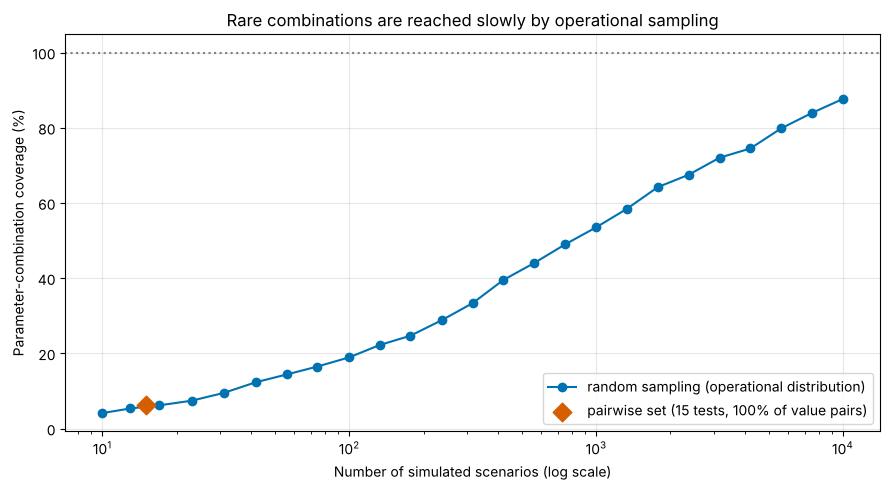

--- Text summary --- coverage after 10,000 samples: 87.7%; 100% not reached in this range.
Rare combinations need targeted (e.g. importance-sampled) generation, not more random driving.


In [9]:
print("> Illustrative data: the sampling probabilities are assumptions, not measured exposure.")
probs = {
    'Weather': [0.7, 0.2, 0.1], 'Time': [0.6, 0.2, 0.2], 'Traffic': [0.5, 0.3, 0.2],
    'Road': [0.7, 0.25, 0.05], 'Obstacles': [0.8, 0.15, 0.05],
}

def sample_scenarios(n, rng):
    cols = {p: rng.choice(parameters[p], size=n, p=probs[p]) for p in names}
    return pd.DataFrame(cols)

sim = sample_scenarios(10_000, rng)
unique_tested = set(map(tuple, sim[names].to_numpy()))
coverage = len(unique_tested) / len(all_combinations)
untested = pd.DataFrame(sorted(set(all_combinations) - unique_tested), columns=names)

print(f"Simulated scenarios          : {len(sim):,}")
print(f"Distinct combinations covered: {len(unique_tested)} / {len(all_combinations)} ({coverage:.1%})")
print(f"Combinations never sampled   : {len(untested)}")
if len(untested):
    print("Values over-represented among the never-sampled combinations:")
    for c in names:
        top = untested[c].value_counts()
        print(f"  {c:9s}: {top.index[0]} ({top.iloc[0]} of {len(untested)})")

# Coverage growth: random operational sampling vs the pairwise set
ns = np.unique(np.logspace(1, 4, 25).astype(int))
cov_curve = []
for n in ns:
    s = sim.iloc[:n]  # first n of the same 10,000 samples
    cov_curve.append(len(set(map(tuple, s[names].to_numpy()))) / len(all_combinations))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ns, np.array(cov_curve) * 100, marker='o', color=OKABE[4], label='random sampling (operational distribution)')
ax.axhline(100, color='grey', ls=':')
ax.scatter([len(pairwise_tests)], [len(pairwise_tests) / len(all_combinations) * 100], color=OKABE[5], marker='D',
           s=90, zorder=3, label=f'pairwise set ({len(pairwise_tests)} tests, 100% of value pairs)')
ax.set_xscale('log')
ax.set_xlabel('Number of simulated scenarios (log scale)')
ax.set_ylabel('Parameter-combination coverage (%)')
ax.set_title('Rare combinations are reached slowly by operational sampling')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()
n_full = ns[np.argmax(np.array(cov_curve) >= 1.0)] if max(cov_curve) >= 1.0 else None
print(f"--- Text summary --- coverage after {ns[-1]:,} samples: {cov_curve[-1]:.1%}; "
      + (f"100% first reached at about {n_full:,} samples." if n_full else "100% not reached in this range."))
print("Rare combinations need targeted (e.g. importance-sampled) generation, not more random driving.")

---

## Case study: campus shuttle

**System:** driverless campus shuttle (automated driving system)

**ODD (illustrative):**
- Geography: university campus roads only
- Speed: maximum 25 km/h
- Time: 07:00–22:00
- Weather: clear to light rain
- Roads: paved, marked lanes

**Task:** identify corner cases — and **separate them from ODD-exit conditions**.

> **Rule:** conditions **outside the ODD** (e.g. snow, dense fog, operation at 23:00) are not in-ODD corner cases. They require **ODD-boundary detection and a transition to a minimal risk condition**, not in-ODD performance validation. Both must be tested, but against different requirements.

In [10]:
print("> Illustrative data: likelihood, severity and test status are assumptions for teaching.")
campus = pd.DataFrame([
    (1, 'Rush hour + event (football match)', 'Yes', 'High', 'High', 'Yes'),
    (2, 'Night + fog + pedestrians crossing mid-block', 'No (dense fog outside ODD)', 'Medium', 'Critical', 'No'),
    (3, 'Construction zone + temporary signs', 'Yes', 'High', 'Medium', 'Yes'),
    (4, 'Heavy rain + puddles obscuring lanes', 'No (heavy rain outside ODD)', 'Medium', 'Medium', 'Partial'),
    (5, 'Bike-lane merge + group of cyclists', 'Yes', 'Medium', 'High', 'No'),
    (6, 'Delivery truck parked blocking lane', 'Yes', 'High', 'Medium', 'Yes'),
    (7, 'Scooters/skateboards in roadway', 'Yes', 'High', 'High', 'No'),
    (8, 'Emergency vehicle approaching', 'Yes', 'Low', 'High', 'Partial'),
    (9, 'Fallen branch after storm', 'Yes', 'Low', 'Medium', 'No'),
    (10, 'Campus police directing traffic', 'Yes', 'Low', 'High', 'No'),
    (11, 'Graduation ceremony crowd crossing', 'Yes', 'Low', 'Critical', 'No'),
    (12, 'Snow + GNSS outage', 'No (snow outside ODD)', 'Low', 'High', 'No'),
    (13, 'Low sun glare + wet-road reflections', 'Yes', 'Medium', 'Medium', 'Partial'),
    (14, 'Multiple shuttles at the same stop', 'Yes', 'Medium', 'Low', 'Yes'),
    (15, 'Dog off-leash running into road', 'Yes', 'Low', 'Critical', 'No'),
], columns=['ID', 'Corner_case', 'In_ODD', 'Likelihood', 'Severity', 'Currently_tested'])
display(campus)

L = {'Low': 1, 'Medium': 2, 'High': 3}
S = {'Low': 1, 'Medium': 2, 'High': 3, 'Critical': 4}
campus['Risk_score'] = campus['Likelihood'].map(L) * campus['Severity'].map(S)
campus['in_odd'] = campus['In_ODD'].str.startswith('Yes')

in_odd = campus[campus['in_odd']]
odd_exit = campus[~campus['in_odd']]
untested_hi = in_odd[(in_odd['Currently_tested'] == 'No') & (in_odd['Risk_score'] >= 6)].sort_values('Risk_score', ascending=False)
rare_severe = in_odd[(in_odd['Likelihood'] == 'Low') & (in_odd['Severity'] == 'Critical')]

print(f"In-ODD corner cases: {len(in_odd)} | ODD-exit conditions: {len(odd_exit)}")
print("\nHIGH PRIORITY by likelihood x severity (in ODD, untested, score >= 6):")
for _, r in untested_hi.iterrows():
    print(f"  {r['ID']:2d}. {r['Corner_case']}  (L={r['Likelihood']}, S={r['Severity']}, score={r['Risk_score']})")
print("\nAlso required by the long-tail view (in ODD, rare but critical):")
for _, r in rare_severe.iterrows():
    print(f"  {r['ID']:2d}. {r['Corner_case']}  (tested: {r['Currently_tested']})")
print("\nODD-exit conditions -> verify detection + minimal risk manoeuvre:")
for _, r in odd_exit.iterrows():
    print(f"  {r['ID']:2d}. {r['Corner_case']}  [{r['In_ODD']}]")

> Illustrative data: likelihood, severity and test status are assumptions for teaching.


,ID,Corner_case,In_ODD,Likelihood,Severity,Currently_tested
0,1,Rush hour + event (football match),Yes,High,High,Yes
1,2,Night + fog + pedestrians crossing mid-block,No (dense fog outside ODD),Medium,Critical,No
2,3,Construction zone + temporary signs,Yes,High,Medium,Yes
3,4,Heavy rain + puddles obscuring lanes,No (heavy rain outside ODD),Medium,Medium,Partial
4,5,Bike-lane merge + group of cyclists,Yes,Medium,High,No
5,6,Delivery truck parked blocking lane,Yes,High,Medium,Yes
6,7,Scooters/skateboards in roadway,Yes,High,High,No
7,8,Emergency vehicle approaching,Yes,Low,High,Partial
8,9,Fallen branch after storm,Yes,Low,Medium,No
9,10,Campus police directing traffic,Yes,Low,High,No


In-ODD corner cases: 12 | ODD-exit conditions: 3

HIGH PRIORITY by likelihood x severity (in ODD, untested, score >= 6):
   7. Scooters/skateboards in roadway  (L=High, S=High, score=9)
   5. Bike-lane merge + group of cyclists  (L=Medium, S=High, score=6)

Also required by the long-tail view (in ODD, rare but critical):
  11. Graduation ceremony crowd crossing  (tested: No)
  15. Dog off-leash running into road  (tested: No)

ODD-exit conditions -> verify detection + minimal risk manoeuvre:
   2. Night + fog + pedestrians crossing mid-block  [No (dense fog outside ODD)]
   4. Heavy rain + puddles obscuring lanes  [No (heavy rain outside ODD)]
  12. Snow + GNSS outage  [No (snow outside ODD)]


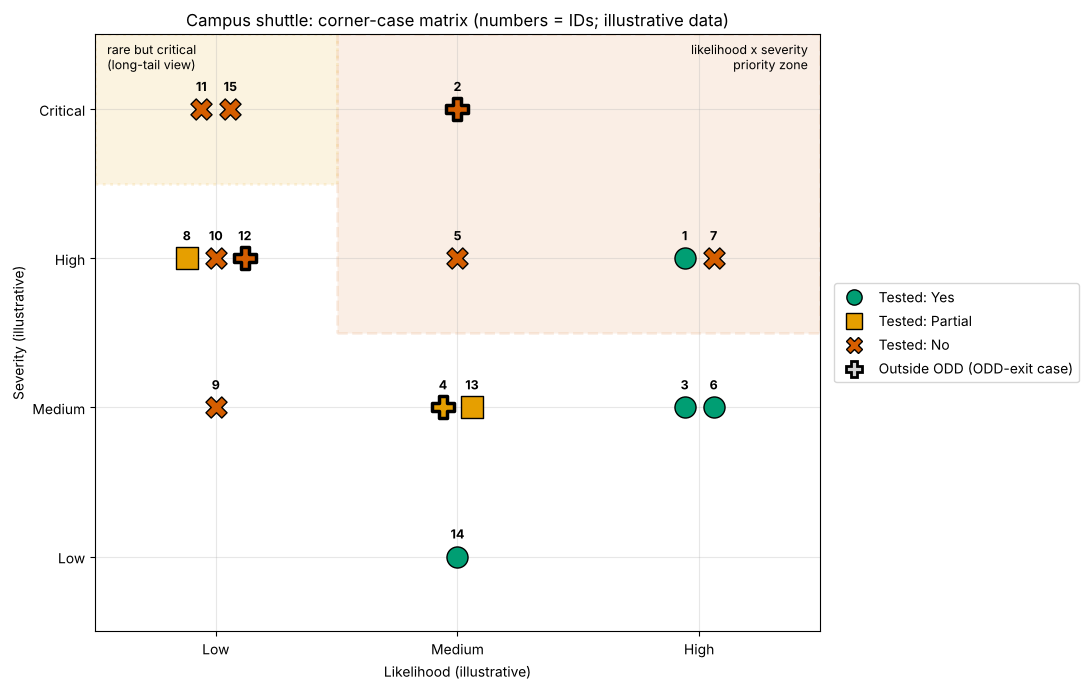

--- Action plan (derived) ---
  1. Test 2 untested in-ODD cases in the priority zone: [7, 5]
  2. Add targeted tests for 2 rare-but-critical in-ODD cases: [11, 15]
  3. Verify ODD-exit detection and minimal risk manoeuvre for: [2, 4, 12]
  4. Add all to the simulation catalogue; confirm selected cases on a proving ground.


In [11]:
fig, ax = plt.subplots(figsize=(11, 7))
offs = campus.groupby(['Likelihood', 'Severity']).cumcount()
n_cell = campus.groupby(['Likelihood', 'Severity'])['ID'].transform('count')
dx = (offs - (n_cell - 1) / 2) * 0.12
for _, r in campus.iterrows():
    col, mk = style[r['Currently_tested']]
    x, y = L[r['Likelihood']] + dx[r.name], S[r['Severity']]
    ax.scatter(x, y, s=230, color=col, marker=mk if r['in_odd'] else 'P', edgecolors='k',
               linewidths=2.5 if not r['in_odd'] else 1, zorder=3)
    ax.annotate(str(r['ID']), (x, y), xytext=(0, 13), textcoords='offset points', ha='center',
                fontsize=9, fontweight='bold', zorder=4)
ax.add_patch(Rectangle((1.5, 2.5), 2, 2, facecolor=OKABE[5], alpha=0.10, edgecolor=OKABE[5], ls='--', lw=2))
ax.text(3.45, 4.45, 'likelihood x severity\npriority zone', ha='right', va='top', fontsize=9, color='k')
ax.add_patch(Rectangle((0.5, 3.5), 1.0, 1.0, facecolor=OKABE[0], alpha=0.12, edgecolor=OKABE[0], ls=':', lw=2))
ax.text(0.55, 4.45, 'rare but critical\n(long-tail view)', ha='left', va='top', fontsize=9)
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(['Low', 'Medium', 'High'])
ax.set_yticks([1, 2, 3, 4]); ax.set_yticklabels(['Low', 'Medium', 'High', 'Critical'])
ax.set_xlim(0.5, 3.5); ax.set_ylim(0.5, 4.5)
ax.set_xlabel('Likelihood (illustrative)')
ax.set_ylabel('Severity (illustrative)')
ax.set_title('Campus shuttle: corner-case matrix (numbers = IDs; illustrative data)')
handles = [Line2D([0], [0], marker=m, color='w', markerfacecolor=c, markeredgecolor='k', markersize=11, label=f'Tested: {s}')
           for s, (c, m) in style.items()]
handles.append(Line2D([0], [0], marker='P', color='w', markerfacecolor='lightgrey', markeredgecolor='k',
                      markeredgewidth=2, markersize=12, label='Outside ODD (ODD-exit case)'))
ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

print("--- Action plan (derived) ---")
print(f"  1. Test {len(untested_hi)} untested in-ODD cases in the priority zone: {list(untested_hi['ID'])}")
print(f"  2. Add targeted tests for {len(rare_severe)} rare-but-critical in-ODD cases: {list(rare_severe['ID'])}")
print(f"  3. Verify ODD-exit detection and minimal risk manoeuvre for: {list(odd_exit['ID'])}")
print("  4. Add all to the simulation catalogue; confirm selected cases on a proving ground.")

---

## From corner cases to ISO 21448 triggering conditions

ISO 21448:2022 (SOTIF) structures the same problem causally:

**triggering condition** → activates a **functional insufficiency** → **output insufficiency** → **hazardous behaviour** (→ harm, if not controlled)

- A **triggering condition** is a specific condition of a scenario that initiates a system reaction leading to hazardous behaviour (or to an inability to prevent or mitigate reasonably foreseeable indirect misuse). Examples: low sun in the camera's field of view, a person on a scooter in the roadway, a puddle covering lane markings.
- A **functional insufficiency** is either a **specification insufficiency** (the intended behaviour is not adequately specified — e.g. Uber ATG did not consider jaywalking pedestrians) or a **performance insufficiency** (a sensor or algorithm cannot meet its specification — e.g. glare saturates the camera).
- Corner cases are therefore best documented **as combinations of triggering conditions** in a structured catalogue, linked to the functional insufficiency they activate.
- ISO 21448 classifies scenarios into **Areas 1–4** (known/unknown × not hazardous/hazardous). Corner-case identification moves scenarios from Area 3 (unknown hazardous) into Area 2 (known hazardous), where they can be mitigated and verified.
- ISO 34502 provides the **scenario-based evaluation framework** for ADS: critical scenarios are built systematically from perception, traffic and vehicle-motion disturbances. ISO 34503:2023 provides the taxonomy for specifying the **ODD**.

Out of scope for ISO 21448: **E/E faults** (ISO 26262) and **intentional attacks** (ISO/SAE 21434; see Notebook 04).

In [12]:
mapping = pd.DataFrame([
    ('Low sun glare + wet-road reflections', 'Low sun in camera FoV; specular reflections',
     'Performance insufficiency: camera dynamic range / detector', 'Perception'),
    ('Scooters/skateboards in roadway', 'Road user type and position not expected',
     'Specification insufficiency (road-user classes) or ML generalisation', 'Traffic'),
    ('Graduation ceremony crowd crossing', 'Dense, unstructured pedestrian flow',
     'Performance insufficiency: tracking/prediction in crowds', 'Traffic'),
    ('Campus police directing traffic', 'Manual traffic direction overrides signals',
     'Specification insufficiency: gesture interpretation not specified', 'Traffic'),
    ('Heavy rain + puddles obscuring lanes', 'Outside ODD: rain intensity above limit',
     'ODD monitoring must detect -> minimal risk manoeuvre', 'Perception / vehicle motion'),
], columns=['Corner_case', 'Triggering_condition(s)', 'Functional_insufficiency / requirement', 'ISO34502_disturbance'])
display(mapping)
for _, r in mapping.iterrows():
    print(f"- {r['Corner_case']}: TC = {r['Triggering_condition(s)']} | FI = {r['Functional_insufficiency / requirement']}")

,Corner_case,Triggering_condition(s),Functional_insufficiency / requirement,ISO34502_disturbance
0,Low sun glare + wet-road reflections,Low sun in camera FoV; specular reflections,Performance insufficiency: camera dynamic rang...,Perception
1,Scooters/skateboards in roadway,Road user type and position not expected,Specification insufficiency (road-user classes...,Traffic
2,Graduation ceremony crowd crossing,"Dense, unstructured pedestrian flow",Performance insufficiency: tracking/prediction...,Traffic
3,Campus police directing traffic,Manual traffic direction overrides signals,Specification insufficiency: gesture interpret...,Traffic
4,Heavy rain + puddles obscuring lanes,Outside ODD: rain intensity above limit,ODD monitoring must detect -> minimal risk man...,Perception / vehicle motion


- Low sun glare + wet-road reflections: TC = Low sun in camera FoV; specular reflections | FI = Performance insufficiency: camera dynamic range / detector
- Scooters/skateboards in roadway: TC = Road user type and position not expected | FI = Specification insufficiency (road-user classes) or ML generalisation
- Graduation ceremony crowd crossing: TC = Dense, unstructured pedestrian flow | FI = Performance insufficiency: tracking/prediction in crowds
- Campus police directing traffic: TC = Manual traffic direction overrides signals | FI = Specification insufficiency: gesture interpretation not specified
- Heavy rain + puddles obscuring lanes: TC = Outside ODD: rain intensity above limit | FI = ODD monitoring must detect -> minimal risk manoeuvre


---

## Safety perspective

- **SOTIF (Module 04):** corner cases are the raw material for triggering-condition catalogues and for moving scenarios from Area 3 to Area 2 — see [04 · Triggering conditions and scenarios](../04_SOTIF_ISO21448/02_triggering_conditions_and_scenarios.ipynb) and [04 · Simulation-based validation](../04_SOTIF_ISO21448/04_simulation_based_validation.ipynb).
- **Validation targets:** how much testing is "enough" is a statistical question — see [06 · Statistical safety validation](../06_AI_Safety_ISO_PAS_8800/08_statistical_safety_validation.ipynb) and [04 · Criticality metrics and RSS](../04_SOTIF_ISO21448/05_criticality_metrics_and_rss.ipynb).
- **ODD boundaries:** ODD-exit cases need runtime detection and a minimal risk manoeuvre — see [07 · ODD and runtime monitoring](../07_Runtime_Assurance_and_Operations/01_odd_and_runtime_monitoring.ipynb).
- **ML-specific corner cases** (object- and domain-level novelty) lead to out-of-distribution detection — [Notebook 03](03_out_of_distribution_detection.ipynb) — and to ISO/PAS 8800 data requirements ([06 · AI safety standards](../06_AI_Safety_ISO_PAS_8800/01_ai_safety_standards.ipynb)).

---

## Exercise: corner-case identification

**Task:** for the campus shuttle, identify additional corner cases and prioritise them.

**Consider:**
1. Which combinations of triggering conditions create corner cases?
2. Which are inside the ODD, and which are ODD-exit conditions?
3. Which functional insufficiency would each activate?
4. How would you test each in simulation vs on a proving ground?

In [13]:
# TODO: add your corner cases
your_corner_cases = pd.DataFrame({
    'Corner_case': [],          # e.g. 'Fireworks display + crowd + low visibility'
    'In_ODD': [],               # 'Yes' or 'No (reason)'
    'Triggering_conditions': [],
    'Likelihood': [],           # Low, Medium, High
    'Severity': [],             # Low, Medium, High, Critical
    'Mitigation_or_test': [],
})
if len(your_corner_cases) > 0:
    display(your_corner_cases)
else:
    print("Add your corner cases above.")
print("\nReflection questions:")
print("  1. Which corner cases are hardest to test, and why?")
print("  2. Which sensors or algorithms would help detect them?")
print("  3. What is the safe response for each (in ODD vs ODD exit)?")
print("  4. How do you balance coverage against test resources?")

Add your corner cases above.

Reflection questions:
  1. Which corner cases are hardest to test, and why?
  2. Which sensors or algorithms would help detect them?
  3. What is the safe response for each (in ODD vs ODD exit)?
  4. How do you balance coverage against test resources?


---

## Key takeaways

### Definitions
- **Edge case:** one parameter at an ODD boundary; **corner case:** several at once (test engineering)
- In perception/ML, a **corner case** is a rare or novel input (pixel, domain, object, scene, scenario level)
- ISO 21448 speaks of **triggering conditions** activating **functional insufficiencies**

### The challenge
- **Combinatorial explosion:** exhaustive testing is infeasible; pairwise arrays cover all value pairs with a few percent of the tests
- **Long tail:** rare scenarios can dominate residual risk once common scenarios are handled well — and they dominate the **validation effort** (≈ 275 million failure-free miles in the Kalra & Paddock example)
- **ML weakness:** poorer generalisation to rarely seen conditions

### Good practice
1. **Separate in-ODD corner cases from ODD-exit conditions**
2. Combine **likelihood × severity** ranking with **exposure-independent** coverage of severe scenarios
3. Use **simulation** with targeted (importance/search-based) generation, and validate on real data
4. Document corner cases as **triggering-condition combinations** (ISO 21448) and organise scenarios with **ISO 34502** disturbance categories
5. Monitor in deployment and feed new cases back into the catalogue

---

## Self-assessment

1. What is the difference between an edge case and a corner case, and why does the distinction matter for test planning?
2. Explain why the long tail makes it difficult to demonstrate safety by driving alone. Use the zero-failure bound in your answer.
3. A five-parameter ODD has four discrete values per parameter. How many combinations exist, and what strategies reduce the number of required tests?
4. Why is "snow + no GNSS" not an in-ODD corner case for the campus shuttle, and what must be verified instead?
5. Give one corner case and express it as triggering condition(s) and the functional insufficiency it activates (ISO 21448).

<details>
<summary><b>Show answers</b></summary>

1. An edge case puts one parameter at its ODD limit; a corner case combines several limits. Edge cases can be covered systematically by boundary-value tests; corner cases explode combinatorially and need prioritisation (risk, covering arrays, search-based generation).
2. Rare events must be observed often enough to bound their rate. With zero failures, showing a rate below λ with confidence c requires n = −ln(1−c)/λ miles — ≈ 275 million miles for λ = 1.09 per 100 million miles and c = 95%. Driving alone is therefore impractical; simulation, scenario-based testing and argumentation are needed.
3. 4^5 = 1,024 combinations. Reduce with equivalence classes, pairwise or t-way covering arrays, risk-based prioritisation, and importance sampling/search-based testing for rare critical combinations.
4. Snow is outside the specified ODD ("clear to light rain"). The requirement is not good performance in snow, but **reliable detection of the ODD exit** and a safe **transition to a minimal risk condition**.
5. Example: "low sun in the camera's field of view on a wet road" (triggering conditions) activates a **performance insufficiency** of the camera-based detector (saturation, reduced contrast), which can lead to a missed pedestrian (output insufficiency) and late braking (hazardous behaviour).

</details>

---

## References

- Breitenstein, J., Termöhlen, J.-A., Lipinski, D., Fingscheidt, T. (2020). Systematization of Corner Cases for Visual Perception in Automated Driving. *IEEE Intelligent Vehicles Symposium (IV)*. https://doi.org/10.1109/IV47402.2020.9304789
- Heidecker, F., Breitenstein, J., Rösch, K., et al. (2021). An Application-Driven Conceptualization of Corner Cases for Perception in Highly Automated Driving. *IEEE IV*. https://doi.org/10.1109/IV48863.2021.9575933
- Kalra, N., Paddock, S. M. (2016). Driving to safety: How many miles of driving would it take to demonstrate autonomous vehicle reliability? *Transportation Research Part A*, 94, 182–193. https://doi.org/10.1016/j.tra.2016.09.010
- Feng, S., Sun, H., Yan, X., et al. (2023). Dense reinforcement learning for safety validation of autonomous vehicles. *Nature*, 615, 620–627. https://doi.org/10.1038/s41586-023-05732-2
- Kuhn, D. R., Wallace, D. R., Gallo, A. M. (2004). Software fault interactions and implications for software testing. *IEEE Transactions on Software Engineering*, 30(6), 418–421. https://doi.org/10.1109/TSE.2004.24
- NIST. *Automated Combinatorial Testing for Software (ACTS)*. https://csrc.nist.gov/projects/automated-combinatorial-testing-for-software
- ISO 21448:2022. *Road vehicles — Safety of the intended functionality*.
- ISO 34502:2022. *Road vehicles — Test scenarios for automated driving systems — Scenario based safety evaluation framework*.
- ISO 34503:2023. *Road vehicles — Test scenarios for automated driving systems — Specification for operational design domain*.

**Related work by the author**
- Patel, M., Jung, R., Khatun, M. (2025). A Systematic Literature Review on Safety of the Intended Functionality for Automated Driving Systems. SAE Technical Paper 2025-01-5030. https://doi.org/10.4271/2025-01-5030
- Patel, M., Jung, R. (2024). Simulation-Based Performance Evaluation of 3D Object Detection Methods with Deep Learning for a LiDAR Point Cloud Dataset in a SOTIF-related Use Case. *VEHITS 2024*. https://doi.org/10.5220/0012707300003702

---

## Further practice

External repository (the author's companion workshop):
- [Notebook 03 — Environmental Degradation](https://github.com/milinpatel07/AI-Perception-Safety-Workshop/blob/main/notebooks/03_environmental_degradation.ipynb)
- [Notebook 04 — Adversarial Attacks](https://github.com/milinpatel07/AI-Perception-Safety-Workshop/blob/main/notebooks/04_adversarial_attacks.ipynb)

---

**Navigation:** ← [Incident case studies](01_incident_case_studies.ipynb) · [Module index](README.md) · [Out-of-distribution detection](03_out_of_distribution_detection.ipynb) →